# Kohonen: sequential hyperparameter tuning

Each stage sweeps one hyperparameter with the others frozen at the best values so far. Every candidate is scored with 5-fold cross-validation x 3 seeds: the SOM is trained on 80% of the creators and evaluated on the 20% it has not seen. Generated by `experiments/run_kohonen_tuning.py`.

In [36]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

project_dir = Path.cwd().resolve()
if not (project_dir / "src").is_dir():
    project_dir = project_dir.parent
if str(project_dir) not in sys.path:
    sys.path.insert(0, str(project_dir))

from src.tp4.kohonen.visualization import plot_som_grid, visualize_som_weights, visualize_u_matrix

results_dir = project_dir / "results"
models_dir = results_dir / "kohonen_models"

tuning = pd.read_csv(results_dir / "kohonen_tuning.csv")
with open(results_dir / "kohonen_best_config.json", encoding="utf-8") as f:
    best = json.load(f)

print("Final config:", json.dumps(best["config"], indent=2))

Final config: {
  "map_size": 6,
  "grid_type": "hexagonal",
  "learning_rate": 0.3,
  "n_iterations": 3000,
  "initial_radius": 6
}


## Stage summary

Mean over folds and seeds. **heldout_qe** ranks the candidates; **heldout_te** (topographic error) is reported next to it; **train_qe** shows how much the map memorises.

In [37]:
stage_tables = {}
for (stage, param), g in tuning.groupby(["stage", "param"], sort=True):
    stage_tables[param] = (
        g.groupby("value")
        .agg(heldout_qe=("heldout_qe", "mean"), heldout_qe_std=("heldout_qe", "std"),
             heldout_te=("heldout_te", "mean"), train_qe=("train_qe", "mean"))
        .sort_values("heldout_qe")
    )
    print(f"Stage {stage}: {param}")
    display(stage_tables[param].round(4))

Stage 0: map_size


,heldout_qe,heldout_qe_std,heldout_te,train_qe
value,,,,
12,3.5219,0.2639,0.5400,0.5351
15,3.5475,0.2893,0.6400,0.1940
14,3.5476,0.2816,0.6533,0.2852
10,3.5966,0.3148,0.5467,1.1286
8,3.6416,0.2778,0.4400,1.8414
7,3.7299,0.3563,0.5200,2.2331
6,3.7358,0.3605,0.3667,2.6307
5,3.8108,0.3307,0.3600,2.9913
4,3.8828,0.3131,0.2667,3.3258


Stage 1: learning_rate


,heldout_qe,heldout_qe_std,heldout_te,train_qe
value,,,,
0.3,3.7138,0.3357,0.4000,2.6050
0.1,3.7211,0.3125,0.2467,2.8277
0.5,3.7358,0.3605,0.3667,2.6307
0.7,3.7523,0.2919,0.4267,2.6470
0.9,3.7907,0.3502,0.4400,2.6768


Stage 2: n_iterations


,heldout_qe,heldout_qe_std,heldout_te,train_qe
value,,,,
3000,3.6688,0.2609,0.3600,2.5270
500,3.6792,0.2882,0.3533,2.7284
5000,3.6801,0.2694,0.4133,2.4898
2000,3.6837,0.2943,0.4600,2.5402
1000,3.7138,0.3357,0.4000,2.6050


Stage 3: initial_radius


,heldout_qe,heldout_qe_std,heldout_te,train_qe
value,,,,
6,3.6688,0.2609,0.3600,2.5270
4,3.6749,0.3181,0.4267,2.5297
8,3.6817,0.2473,0.4267,2.5440
2,3.6873,0.2729,0.4200,2.5058
3,3.7001,0.2689,0.3333,2.4840


Stage 4: grid_type


,heldout_qe,heldout_qe_std,heldout_te,train_qe
value,,,,
rectangular,3.6688,0.2609,0.3600,2.5270
hexagonal,3.7078,0.2985,0.1067,2.7564


## Effect of each hyperparameter

Points are individual runs (fold x seed), the line is the mean. The red circle is the stage winner (chosen on held-out QE). Differences smaller than the spread of the points are not meaningful.

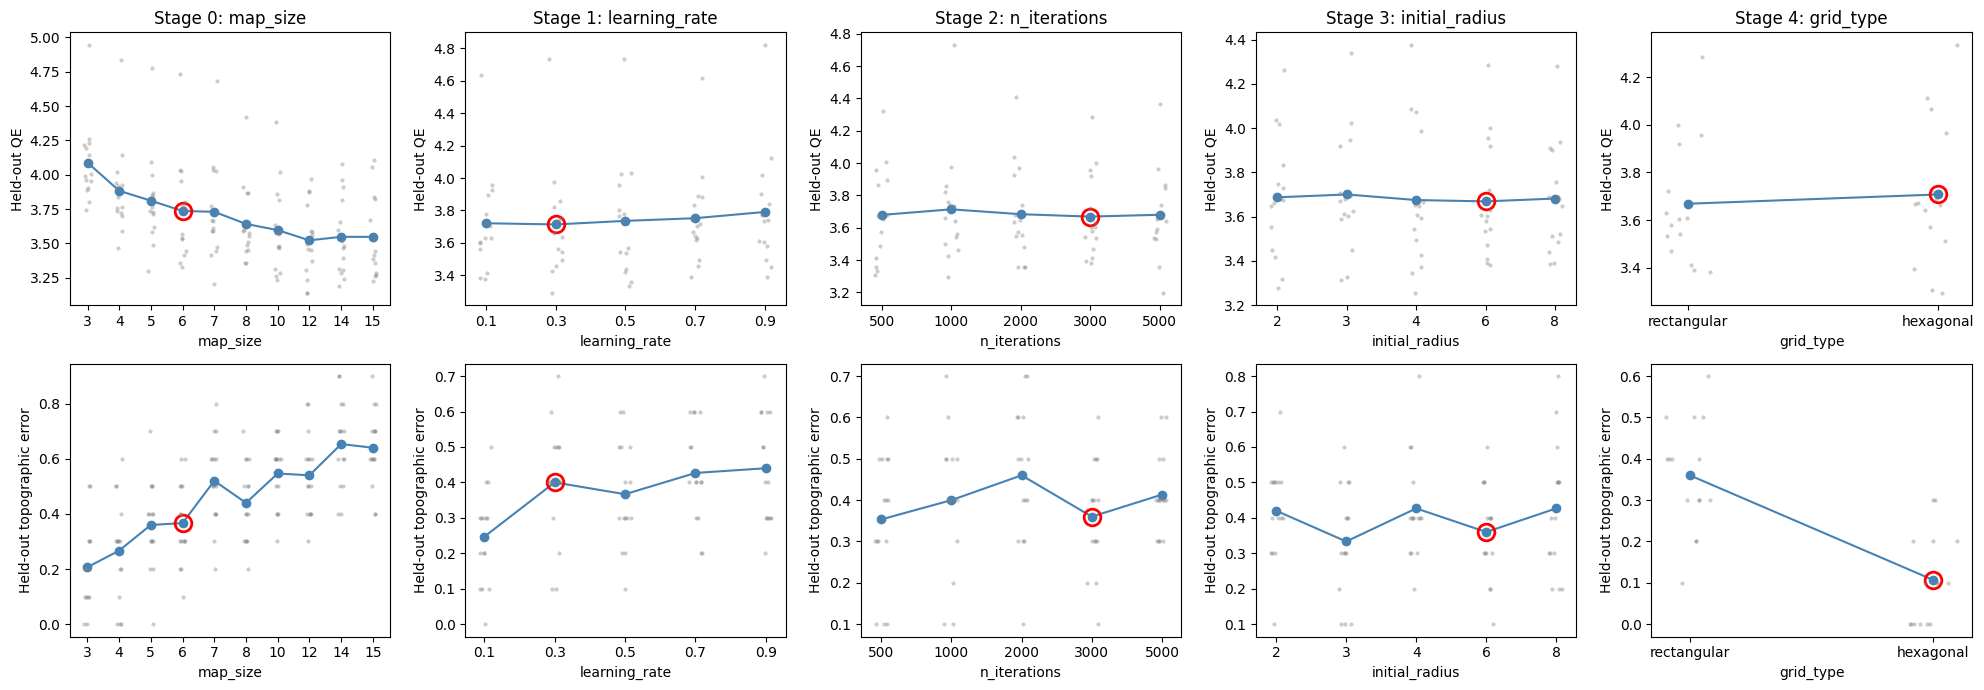

In [38]:
stages = tuning[["stage", "param"]].drop_duplicates().sort_values("stage")
winners = {w["param"]: w["winner"] for w in best["winners"]}

metrics = [("heldout_qe", "Held-out QE"), ("heldout_te", "Held-out topographic error")]
fig, axes = plt.subplots(2, len(stages), figsize=(4 * len(stages), 7), squeeze=False)
for col, (_, row) in enumerate(stages.iterrows()):
    param = row["param"]
    g = tuning[tuning["param"] == param].copy()
    g["value"] = g["value"].astype(str)
    order = list(dict.fromkeys(g["value"]))
    for r, (metric, label) in enumerate(metrics):
        ax = axes[r, col]
        sns.stripplot(data=g, x="value", y=metric, order=order, color="gray", alpha=0.4, size=3, ax=ax)
        mean = g.groupby("value")[metric].mean().loc[order]
        ax.plot(range(len(order)), mean.values, color="steelblue", marker="o")
        win = str(winners[param])
        ax.plot(order.index(win), mean[win], "o", color="red", markersize=12, mfc="none", mew=2)
        ax.set_xlabel(param)
        ax.set_ylabel(label)
        if r == 0:
            ax.set_title(f"Stage {int(row['stage'])}: {param}")
plt.tight_layout()
plt.show()

## Neuron usage per stage

In [39]:
usage = tuning.assign(usage_ratio=tuning["used_neurons"] / tuning["total_neurons"])
display(usage.groupby(["param", "value"])["usage_ratio"].mean().round(3).to_frame("mean usage ratio"))

mean usage ratio
param          value                        
grid_type      hexagonal               0.693
               rectangular             0.693
initial_radius 2                       0.689
               3                       0.669
               4                       0.711
               6                       0.693
               8                       0.691
learning_rate  0.1                     0.719
               0.3                     0.683
               0.5                     0.693
               0.7                     0.691
               0.9                     0.707
map_size       10                      0.378
               12                      0.277
               14                      0.204
               15                      0.178
               3                       0.993
               4                       0.921
               5                       0.840
               6                       0.693
               7                       0.601
               8                       0.511
n_iterations   1000                    0.683
               2000                    0.693
               3000                    0.693
               500                     0.687
               5000                    0.685

## Final model

In [40]:
with np.load(models_dir / "som_tuned.npz") as saved:
    weights = saved["weights"]
    bmu_counts = saved["bmu_counts"]
    bmu_indices = saved["bmu_indices"]
    u_matrix = saved["u_matrix"]
    feature_names = saved["feature_names"].tolist()
with open(models_dir / "som_tuned.json", encoding="utf-8") as f:
    metadata = json.load(f)
grid_type = metadata["grid_type"]
print(json.dumps(metadata, indent=2))

{
  "map_size": 6,
  "grid_type": "hexagonal",
  "learning_rate": 0.3,
  "n_iterations": 3000,
  "initial_radius": 6,
  "seed": 0,
  "train_quantization_error": 2.8491294048511633,
  "train_topographic_error": 0.04,
  "used_neurons": 26,
  "total_neurons": 36
}


## Component planes

One map per feature, coloured by the neuron's standardized weight. Top row: the 4 features whose weights vary most across the map. Bottom row: the topic percentages (one topic per client). Read a region by looking at the same cell across planes.

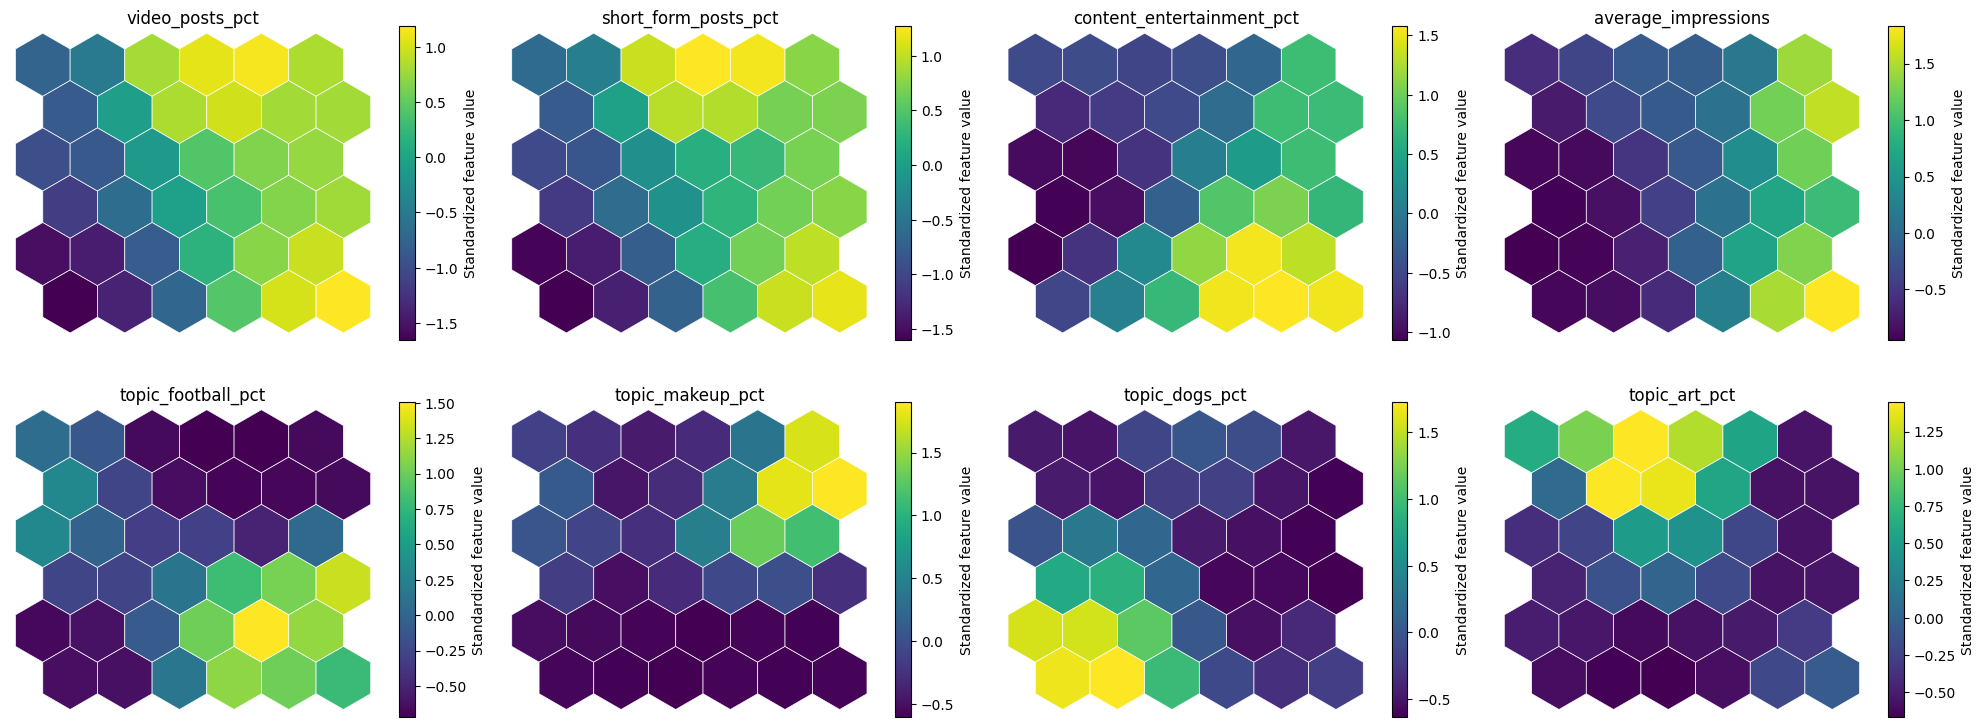

In [41]:
spread = weights.reshape(-1, weights.shape[2]).std(axis=0)
top_features = [feature_names[k] for k in np.argsort(-spread)[:4]]
topic_features = [f for f in feature_names if f.startswith("topic_")]
selected = top_features + topic_features

n_cols = 4
n_rows = int(np.ceil(len(selected) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4 * n_rows), squeeze=False)
for ax, name in zip(axes.ravel(), selected):
    visualize_som_weights(weights, feature_names.index(name), grid_type=grid_type,
                          feature_name=name, ax=ax)
for ax in axes.ravel()[len(selected):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

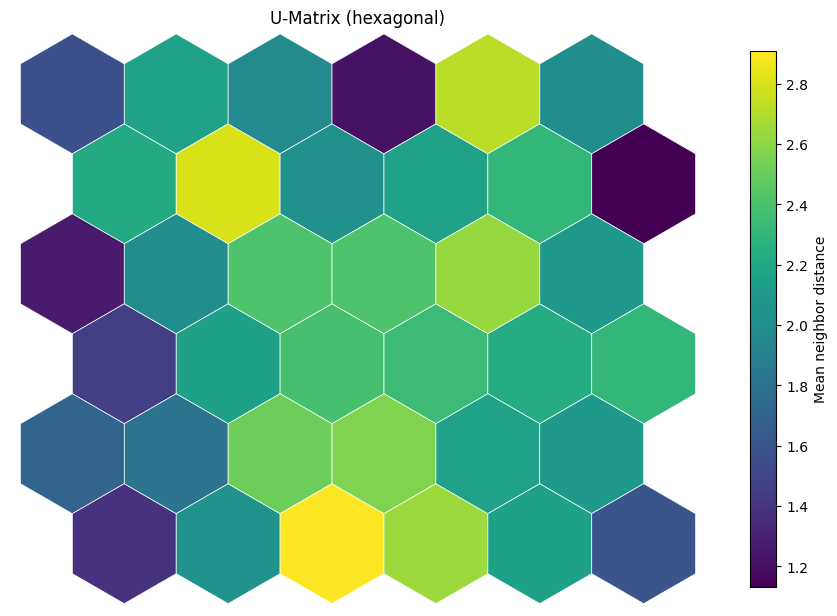

In [42]:
visualize_u_matrix(u_matrix, grid_type=grid_type)

## Creators on the U-matrix

Each creator is written on the neuron that is its BMU. Bright cells of the U-matrix are borders between groups; names are a sanity check, not evidence (check the component planes).

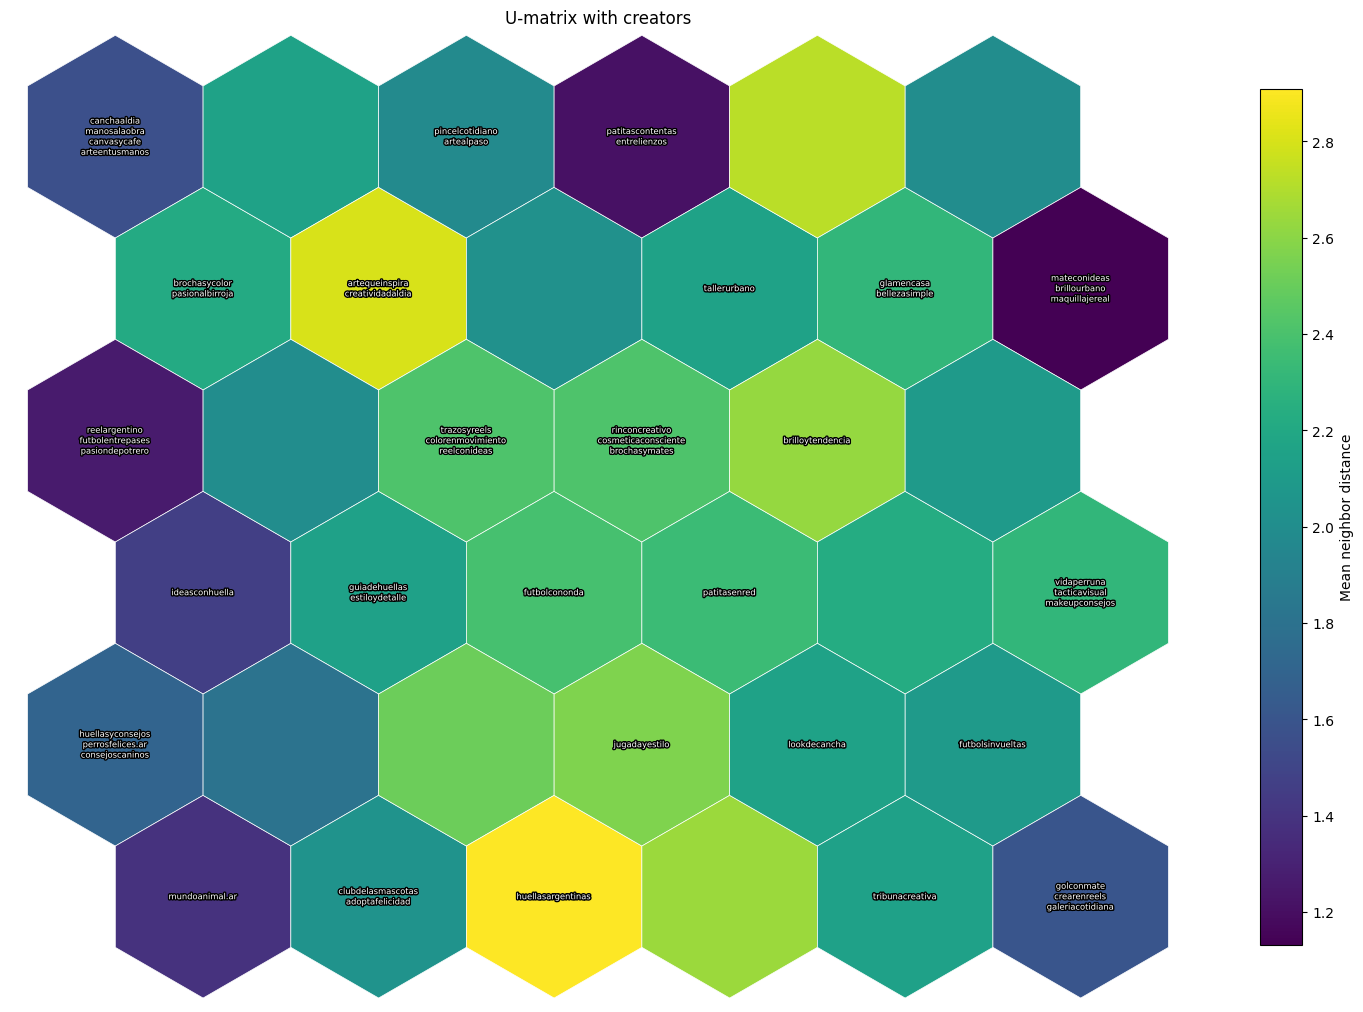

In [43]:
names = pd.read_csv(project_dir / "data" / "creadores.csv")["name"].tolist()
cell_names = {}
for name, (i, j) in zip(names, bmu_indices):
    cell_names.setdefault((int(i), int(j)), []).append(name.lstrip("@"))
labels = {cell: "\n".join(v) for cell, v in cell_names.items()}

plot_som_grid(u_matrix, grid_type=grid_type, title="U-matrix with creators",
              colorbar_label="Mean neighbor distance", labels=labels, figsize=(15, 11))

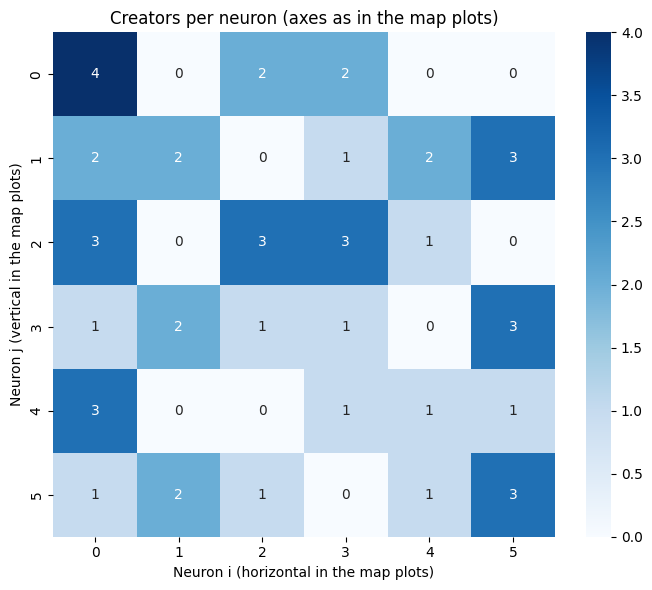

In [44]:
plt.figure(figsize=(7, 6))
sns.heatmap(bmu_counts.T, annot=True, fmt="d", cmap="Blues")
plt.title("Creators per neuron (axes as in the map plots)")
plt.xlabel("Neuron i (horizontal in the map plots)")
plt.ylabel("Neuron j (vertical in the map plots)")
plt.tight_layout()
plt.show()

## Evidence for the analysis

The cells in this section only compute and plot. Interpreting them is left to the notes below.

In [45]:
from src.tp4.data import load_creators, standardise
from src.tp4.linear.pca import fit_pca, loadings_df

df = load_creators(project_dir / "data" / "creadores.csv")
assert df.columns.tolist() == feature_names, "notebook features differ from the trained map"
topic_cols = [c for c in df.columns if c.startswith("topic_")]
dominant_topic = df[topic_cols].idxmax(axis=1).str.replace("topic_", "").str.replace("_pct", "")

creators = pd.DataFrame({
    "name": names, "i": bmu_indices[:, 0], "j": bmu_indices[:, 1],
    "dominant_topic": dominant_topic,
}).join(df[top_features])

neuron_table = creators.groupby(["i", "j"]).agg(
    n_creators=("name", "size"),
    creators=("name", ", ".join),
    topics=("dominant_topic", lambda s: ", ".join(sorted(set(s)))),
    **{f: (f, "mean") for f in top_features},
).round(1)
display(neuron_table)
single_topic = (~neuron_table["topics"].str.contains(",")).sum()
print(f"{single_topic} of {len(neuron_table)} used neurons contain a single dominant topic")

n_creators                                           creators  \
i j                                                                  
0 0           4  @canchaaldia, @manosalaobra, @canvasycafe, @ar...   
  1           2                   @brochasycolor, @pasionalbirroja   
  2           3  @reelargentino, @futbolentrepases, @pasiondepo...   
  3           1                                    @ideasconhuella   
  4           3  @huellasyconsejos, @perrosfelices.ar, @consejo...   
  5           1                                    @mundoanimal.ar   
1 1           2                 @artequeinspira, @creatividadaldia   
  3           2                    @guiadehuellas, @estiloydetalle   
  5           2               @clubdelasmascotas, @adoptafelicidad   
2 0           2                      @pincelcotidiano, @artealpaso   
  2           3   @trazosyreels, @colorenmovimiento, @reelconideas   
  3           1                                     @futbolcononda   
  5           1                                 @huellasargentinas   
3 0           2                   @patitascontentas, @entrelienzos   
  1           1                                      @tallerurbano   
  2           3  @rinconcreativo, @cosmeticaconsciente, @brocha...   
  3           1                                      @patitasenred   
  4           1                                     @jugadayestilo   
4 1           2                        @glamencasa, @bellezasimple   
  2           1                                  @brilloytendencia   
  4           1                                      @lookdecancha   
  5           1                                   @tribunacreativa   
5 1           3      @mateconideas, @brillourbano, @maquillajereal   
  3           3      @vidaperruna, @tacticavisual, @makeupconsejos   
  4           1                                  @futbolsinvueltas   
  5           3      @golconmate, @crearenreels, @galeriacotidiana   

                  topics  video_posts_pct  short_form_posts_pct  \
i j                                                               
0 0        art, football             45.1                  44.6   
  1     football, makeup             40.1                  32.5   
  2     football, makeup             40.8                  37.0   
  3                 dogs             39.9                  34.5   
  4                 dogs             29.9                  23.9   
  5                 dogs             28.1                  19.6   
1 1                  art             54.7                  52.9   
  3                 dogs             43.2                  42.0   
  5                 dogs             35.8                  33.0   
2 0                  art             61.6                  64.9   
  2        art, football             56.3                  56.4   
  3             football             53.1                  54.9   
  5                 dogs             49.9                  48.9   
3 0            art, dogs             71.6                  73.5   
  1               makeup             66.4                  65.7   
  2          art, makeup             56.6                  49.7   
  3                 dogs             58.5                  54.2   
  4             football             57.4                  50.8   
4 1               makeup             65.6                  60.7   
  2               makeup             58.8                  52.2   
  4             football             59.3                  60.8   
  5             football             66.8                  66.7   
5 1               makeup             64.4                  63.9   
  3             football             62.4                  62.4   
  4             football             70.8                  68.4   
  5  art, dogs, football             69.4                  69.6   

     content_entertainment_pct  average_impressions  
i j                                                  
0 0                       17.5              44710.0  
  1  

19 of 26 used neurons contain a single dominant topic


In [46]:
X_all, _ = standardise(df)
pca = fit_pca(X_all)
scores = pca.transform(X_all)
print("Explained variance ratio PC1, PC2:", pca.explained_variance_ratio_[:2].round(3))

load = loadings_df(pca, feature_names)
for pc in ["PC1", "PC2"]:
    print(f"\n{pc}: strongest loadings")
    display(load[pc].reindex(load[pc].abs().sort_values(ascending=False).index).head(8).round(2).to_frame())

Explained variance ratio PC1, PC2: [0.499 0.094]

PC1: strongest loadings


,PC1
average_caption_words,0.25
average_impressions,-0.25
average_video_views,-0.25
average_reach,-0.25
trend_posts_pct,-0.24
followers,-0.24
price_usd,-0.23
video_posts_pct,-0.23



PC2: strongest loadings


,PC2
argentina_audience_pct,0.40
content_showcase_pct,-0.37
topic_art_pct,-0.36
topic_dogs_pct,0.26
estimated_argentina_reach,0.25
likes_per_1000,-0.23
monthly_posts,-0.23
short_form_posts_pct,-0.22


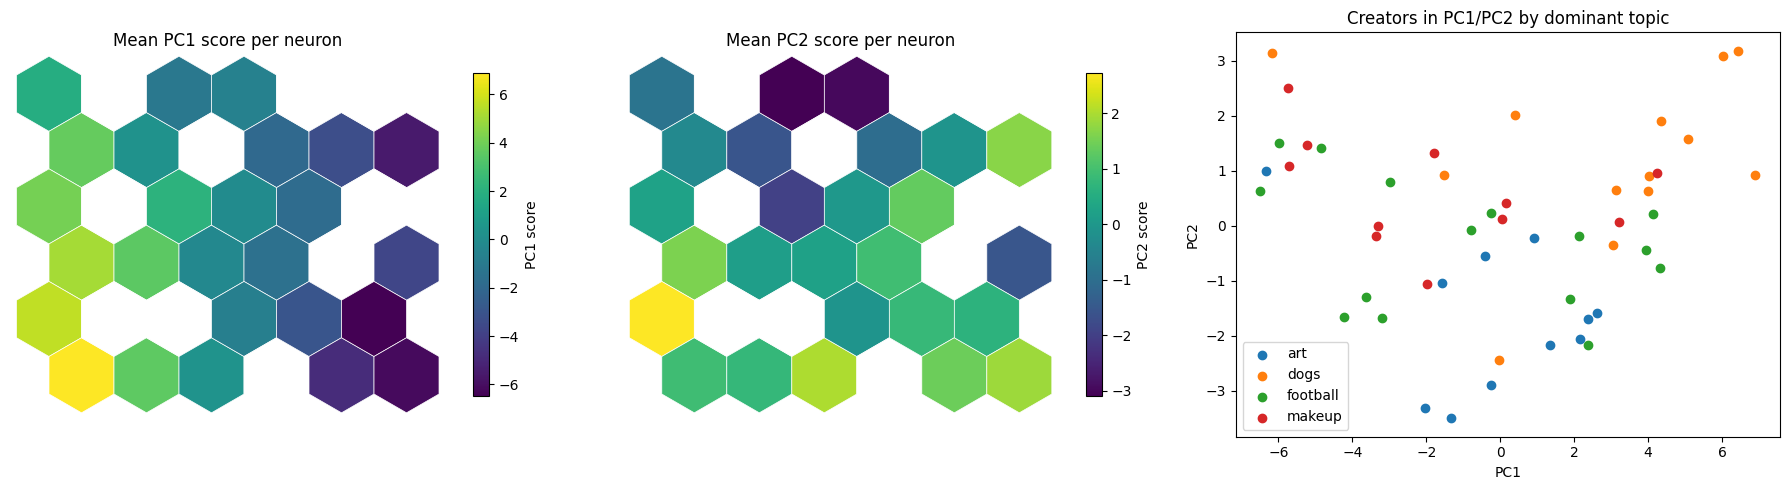

In [47]:
def neuron_mean(values):
    out = np.full(bmu_counts.shape, np.nan)
    for (i, j), idx in creators.groupby(["i", "j"]).groups.items():
        out[i, j] = values[list(idx)].mean()
    return out

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
plot_som_grid(neuron_mean(scores[:, 0]), grid_type=grid_type, title="Mean PC1 score per neuron",
              colorbar_label="PC1 score", ax=axes[0])
plot_som_grid(neuron_mean(scores[:, 1]), grid_type=grid_type, title="Mean PC2 score per neuron",
              colorbar_label="PC2 score", ax=axes[1])
for topic in sorted(dominant_topic.unique()):
    mask = (dominant_topic == topic).to_numpy()
    axes[2].scatter(scores[mask, 0], scores[mask, 1], label=topic)
axes[2].set_xlabel("PC1")
axes[2].set_ylabel("PC2")
axes[2].set_title("Creators in PC1/PC2 by dominant topic")
axes[2].legend()
plt.tight_layout()
plt.show()

In [48]:
used = creators.groupby(["i", "j"]).agg(creators=("name", ", ".join)).reset_index()
used["u"] = [u_matrix[i, j] for i, j in zip(used["i"], used["j"])]
print("Highest U-matrix values among used neurons")
display(used.sort_values("u", ascending=False).head(6).round(2))
print("Lowest U-matrix values among used neurons")
display(used.sort_values("u").head(6).round(2))

Highest U-matrix values among used neurons


,i,j,creators,u
12,2,5,@huellasargentinas,2.91
6,1,1,"@artequeinspira, @creatividadaldia",2.80
19,4,2,@brilloytendencia,2.63
17,3,4,@jugadayestilo,2.56
15,3,2,"@rinconcreativo, @cosmeticaconsciente, @brocha...",2.42
10,2,2,"@trazosyreels, @colorenmovimiento, @reelconideas",2.41


Lowest U-matrix values among used neurons


,i,j,creators,u
22,5,1,"@mateconideas, @brillourbano, @maquillajereal",1.13
13,3,0,"@patitascontentas, @entrelienzos",1.21
2,0,2,"@reelargentino, @futbolentrepases, @pasiondepo...",1.26
5,0,5,@mundoanimal.ar,1.39
3,0,3,@ideasconhuella,1.46
0,0,0,"@canchaaldia, @manosalaobra, @canvasycafe, @ar...",1.57
